In [1]:
DAY_DIR = '2026_06_04'
DS_DIR = "159090" # 208735 73131 159090

In [2]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path

import utils

In [3]:
RQ = "RQ1"
FEA_DIR = utils.FEA_DIR
ROOT = Path("..")


In [4]:
BASE = ROOT / DAY_DIR / DS_DIR

ROB_DIR = ROOT / DAY_DIR / DS_DIR

OUT_DIR = "ImgOut" 
OUT = ROOT / OUT_DIR / DAY_DIR / RQ / DS_DIR
OUT.mkdir(parents=True, exist_ok=True)
OUT_CSV = OUT / "CSV"
OUT_CSV.mkdir(parents=True, exist_ok=True)
OUT_PDF = OUT / "PDF"
OUT_PDF.mkdir(parents=True, exist_ok=True)
OUT_PNG = OUT / "PNG"
OUT_PNG.mkdir(parents=True, exist_ok=True)
INPUT = OUT / "INPUT"


sns.set_theme(style="white", font_scale=0.9)

In [5]:
# -----------------------------
# Locate folder
# -----------------------------
for el in sorted(os.listdir(BASE)):
    if 'k0_iter1' in el:
        break
BASE = os.path.join(BASE, el)
    

In [6]:
dea_files, wgcna_files = utils.read_files(BASE)

dea_labels = [str(utils.dea_thr(f)) for f in dea_files]  # e.g. 50, 60, ... 150
dea_labels = [str(int(x)/100) for x in dea_labels]
wgcna_labels = [f"{a}_{b}" for (a, b) in map(utils.wgcna_thr, wgcna_files)]  # e.g. 60_60, 65_65, ...
wgcna_labels = [f'{int(x[:2])/100:.2f}' for x in wgcna_labels]

In [7]:
# -----------------------------
# Read sets
# -----------------------------
dea_sets = [utils.read_gene_set(os.path.join(BASE, f)) for f in dea_files]
wgcna_sets = [utils.read_gene_set(os.path.join(BASE, f)) for f in wgcna_files]

# -----------------------------
# Compute Jaccard matrices
# -----------------------------
J_dea = utils.compute_intra_jaccard(dea_sets)
J_wgcna = utils.compute_intra_jaccard(wgcna_sets)
J_cross = utils.compute_cross_jaccard(wgcna_sets, dea_sets)

# Put into DataFrames for nicer labels
df_dea = pd.DataFrame(J_dea, index=dea_labels, columns=dea_labels)
df_wgcna = pd.DataFrame(J_wgcna, index=wgcna_labels, columns=wgcna_labels)
df_cross = pd.DataFrame(J_cross, index=wgcna_labels, columns=dea_labels)

# Masks for upper-triangular display (mask = True means hide)
mask_dea = np.triu(np.ones_like(df_dea, dtype=bool), k=0)
mask_wgcna = np.triu(np.ones_like(df_wgcna, dtype=bool), k=0)

dea_sizes = [len(s) for s in dea_sets]
wgcna_sizes = [len(s) for s in wgcna_sets]

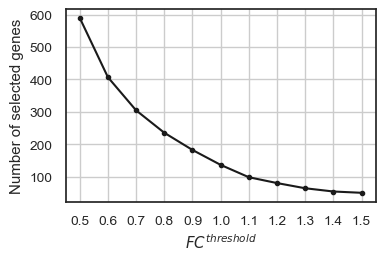

In [8]:
f,ax = plt.subplots(figsize=(4, 2.5))
ax.plot(df_dea.index, dea_sizes,'.-k')
ax.grid()
ax.set_xlabel(utils.APPROACH_SPECS['DEA']['param_name'])
ax.set_ylabel('Number of selected genes')

plt.savefig(os.path.join(OUT_PNG,f'{RQ}_{DS_DIR}_sizes_dea.png'), format='png', dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(OUT_PDF,f'{RQ}_{DS_DIR}_sizes_dea.pdf'), format='pdf', bbox_inches='tight')

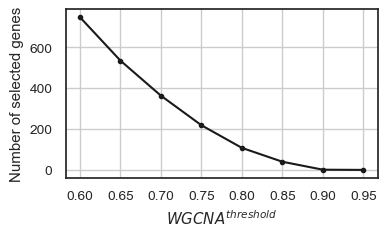

In [9]:
f,ax = plt.subplots(figsize=(4, 2.5))

ax.plot(df_wgcna.index, wgcna_sizes,'.-k')
ax.grid()
ax.set_xlabel(utils.APPROACH_SPECS['WGCNA']['param_name'])
ax.set_ylabel('Number of selected genes')
plt.tight_layout()
plt.savefig(os.path.join(OUT_PNG,f'{RQ}_{DS_DIR}_sizes_wgcna.png'), format='png', dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(OUT_PDF,f'{RQ}_{DS_DIR}_sizes_wgcna.pdf'), format='pdf', bbox_inches='tight')

## GOntoSim

In [10]:
def plot_triangular(mean_matrix, approach, go_category, go_count):
    # mask triangolo superiore
    mask = np.triu(np.ones_like(mean_matrix, dtype=bool), k=1)

    # annotazioni: numeri + NA
    annot = mean_matrix.round(2).astype(object)
    annot = annot.where(~mean_matrix.isna(), "NA")
    
    if approach == 'WGCNA':
        labels = [x.split("_")[0] for x in mean_matrix.index]
        labels = [f"{int(x)*0.01:.2f}" for x in labels]
    else:
        labels = list(mean_matrix.index)
        labels = [f"{int(x)*0.01:.2f}" for x in labels]

    labels = [f"{x}\n({y})" for x, y in zip(labels, go_count)]

    fig, ax = plt.subplots(
        figsize=(len(mean_matrix.columns)*0.6, len(mean_matrix.index)*0.5)
    )

    sns.heatmap(
        mean_matrix,
        ax=ax,
        mask=mask,
        annot=annot,
        fmt="",
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        square=True,
        linewidths=0.5,
        xticklabels=labels,
        yticklabels=labels,
        linecolor="white",
        cbar=False
    )

    name = utils.APPROACH_SPECS[approach]["param_name"]
    ax.set_xlabel(f"{name}\n(Number of GO Terms)")
    ax.set_ylabel(f"{name}\n(Number of GO Terms)")

    ax.set_xticklabels(labels, rotation=0, ha="center")
    ax.set_yticklabels(labels, rotation=0, va="center")

    plt.tight_layout()

    fig.savefig(
        os.path.join(OUT_PNG, f'{RQ}_{DS_DIR}_{approach}_{go_category}.png'),
        format='png',
        dpi=300,
        bbox_inches='tight'
    )
    fig.savefig(
        os.path.join(OUT_PDF, f'{RQ}_{DS_DIR}_{approach}_{go_category}.pdf'),
        format='pdf',
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

/var/folders/27/y8zb96dj4rz5c5pd6d84yd440000gn/T/ipykernel_29080/2389954067.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


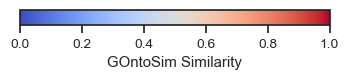

In [11]:
import matplotlib as mpl
def save_colorbar(label="GOntoSim Similarity",
                  cmap="coolwarm",
                  vmin=0,
                  vmax=1,
                  orientation="horizontal",
                  filename_prefix="colorbar_gontosim"):
    
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    if orientation == "vertical":
        fig, ax = plt.subplots(figsize=(1.2, 10))
    else:
        fig, ax = plt.subplots(figsize=(4, 0.2))

    cbar = fig.colorbar(sm, cax=ax, orientation=orientation)
    cbar.set_label(label)

    plt.tight_layout()

    plt.savefig(
        os.path.join(OUT_PNG, f"{filename_prefix}.png"),
        format="png", dpi=300, bbox_inches="tight"
    )
    plt.savefig(
        os.path.join(OUT_PDF, f"{filename_prefix}.pdf"),
        format="pdf", bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)
save_colorbar()

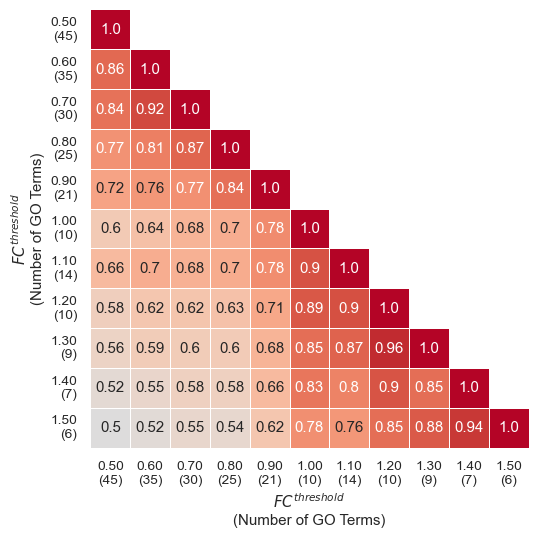

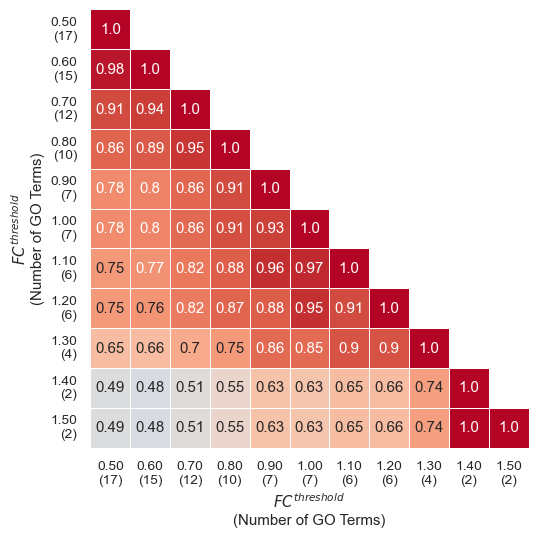

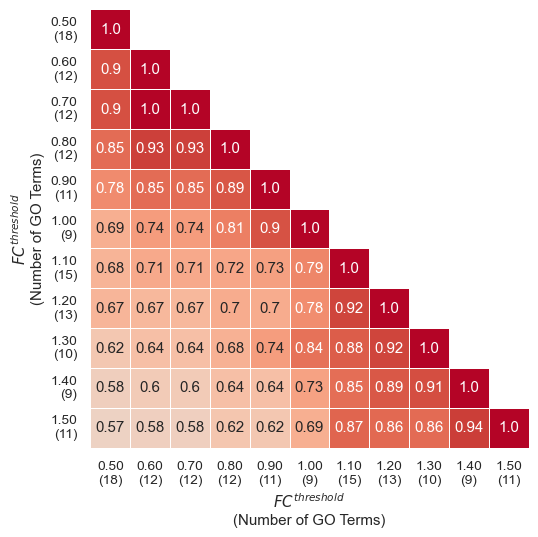

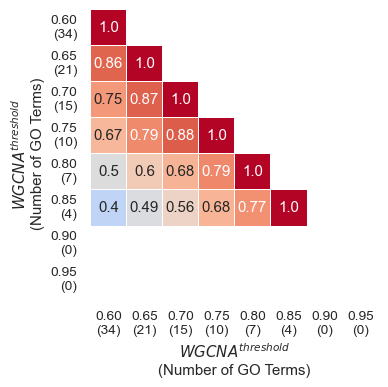

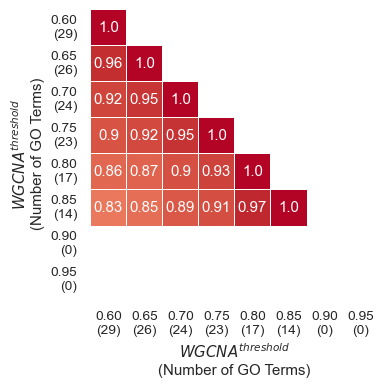

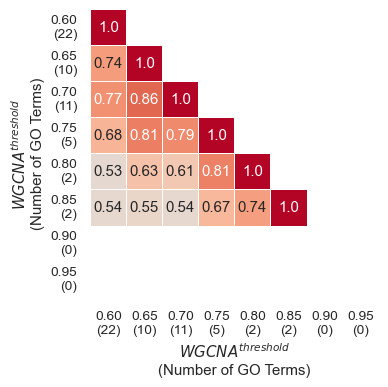

In [12]:

for run in os.listdir(ROB_DIR):
    final_dir = ROB_DIR / run / FEA_DIR
    if "k0" in run:
        for approach in ["DEA", "WGCNA"]:
            params = utils.APPROACH_SPECS[approach]["param_int"]
            for category in utils.GO_CATEGORY_MAP:
                go_count = []

                for param in params:
                    if approach == 'DEA':                
                        df = pd.read_csv(final_dir / f"{approach}_go_{param}.csv")
                    elif approach == 'WGCNA':                
                        df = pd.read_csv(final_dir / f"{approach}_go_{param}_{param}.csv")
                    terms = (
                        df[df.Category == category]["Term"]
                        .dropna()
                        .sort_values()
                        .reset_index(drop=True)
                    )
                    # save CSV

                    out_file = OUT_CSV / f"{RQ}_{DS_DIR}_{approach}_go_{param}_{category}.csv"
                    df_terms = terms.to_frame(name="Term")
                    df_terms.to_csv(out_file, index=False)
                    go_count.append(len(df_terms))
                fname = INPUT / f"{RQ}_{DS_DIR}_{approach}_{utils.GO_CATEGORY_MAP[category]}_mean_similarity.csv"
                df = pd.read_csv(fname, index_col = 0)

                plot_triangular(df, approach, category, go_count)